In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [28]:
rsp = pd.read_excel("RSP Monthly.xlsx")

In [29]:
rsp.head()
rsp.columns
rsp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 5 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    122 non-null    datetime64[ns]
 1   Fund Identifier                         122 non-null    int64         
 2   Total Net Assets as of Month End        122 non-null    float64       
 3   Total Return per Share as of Month End  122 non-null    float64       
 4   Monthly Net Asset Value Per Share       122 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 4.9 KB


In [30]:
rsp = rsp.rename(columns={
    "Date": "date",
    "Total Net Assets as of Month End": "tna",
    "Total Return per Share as of Month End": "ret",
    "Monthly Net Asset Value Per Share": "nav"
})

In [31]:
rsp["ret"].describe()

count    122.000000
mean       0.009895
std        0.047621
min       -0.178824
25%       -0.009619
50%        0.011276
75%        0.036402
max        0.144008
Name: ret, dtype: float64

In [32]:
rsp.columns

Index(['date', 'Fund Identifier', 'tna', 'ret', 'nav'], dtype='object')

In [33]:
rsp.columns = [
    "date",
    "fund_id",
    "tna",
    "ret",
    "nav"
]

In [34]:
rsp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     122 non-null    datetime64[ns]
 1   fund_id  122 non-null    int64         
 2   tna      122 non-null    float64       
 3   ret      122 non-null    float64       
 4   nav      122 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 4.9 KB


In [35]:
rsp["tna_lag"] = rsp["tna"].shift(1)

rsp["net_flow"] = rsp["tna"] - (rsp["tna_lag"] * (1 + rsp["ret"]))

rsp["flow_rsp"] = rsp["net_flow"] / rsp["tna_lag"]

rsp = rsp.dropna()

In [36]:
rsp[["tna", "ret", "net_flow", "flow_rsp"]].head()
rsp["flow_rsp"].describe()

count    121.000000
mean       0.009272
std        0.034149
min       -0.111160
25%       -0.008376
50%        0.002112
75%        0.021748
max        0.146677
Name: flow_rsp, dtype: float64

In [37]:
rsp_flow = rsp[["date", "flow_rsp"]]

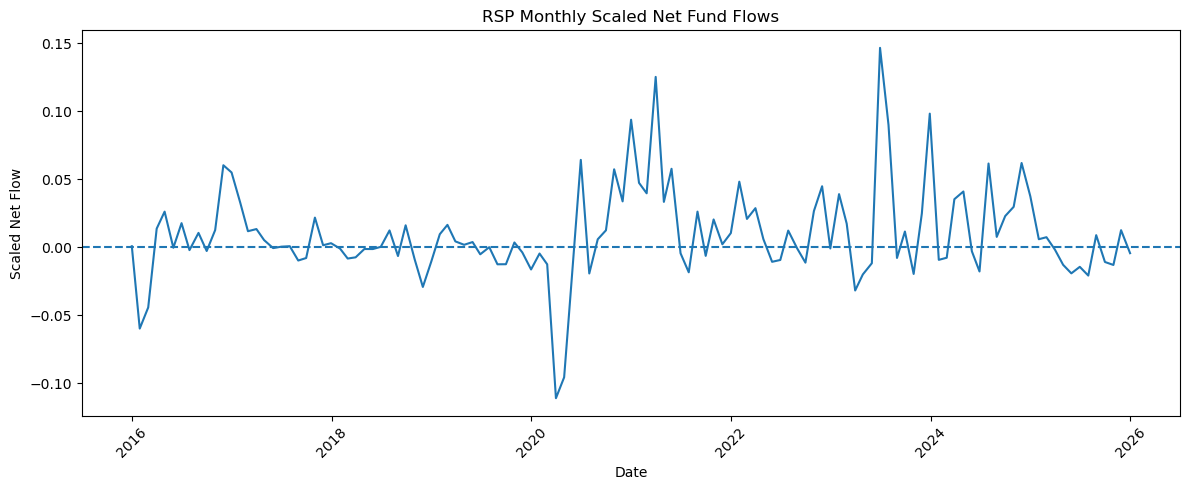

In [38]:
plt.figure(figsize=(12,5))

plt.plot(rsp["date"], rsp["flow_rsp"])
plt.axhline(0, linestyle="--")

plt.title("RSP Monthly Scaled Net Fund Flows")
plt.xlabel("Date")
plt.ylabel("Scaled Net Flow")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [39]:
rsp[["date", "flow_rsp"]].head()

,date,flow_rsp
1,2015-12-31,0.000684
2,2016-01-29,-0.059913
3,2016-02-29,-0.044370
4,2016-03-31,0.013637
5,2016-04-29,0.026139


In [40]:
rsp = rsp.copy()
rsp["date"] = pd.to_datetime(rsp["date"])
rsp["date"] = rsp["date"] + pd.offsets.MonthEnd(0)

In [41]:
rsp.head()

,date,fund_id,tna,ret,nav,tna_lag,net_flow,flow_rsp
1,2015-12-31,27416,9610.1,-0.023333,76.6915,9832.8,6.727892,0.000684
2,2016-01-31,27416,8493.0,-0.056330,72.3715,9610.1,-575.767101,-0.059913
3,2016-02-29,27416,8209.1,0.010942,73.1634,8493.0,-376.831702,-0.044370
4,2016-03-31,27416,8968.6,0.078882,78.5322,8209.1,111.950031,0.013637
5,2016-04-30,27416,9310.2,0.011949,79.4706,8968.6,234.432058,0.026139


In [42]:
rsp_final = rsp[["date", "flow_rsp"]].copy()
rsp_final = rsp_final.sort_values("date")

rsp_final.to_csv("rsp_clean.csv", index=False)